In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
from google.colab import drive

try:
    drive.mount('/content/drive', force_remount=True)
except:
    pass

file_path = "/content/drive/MyDrive/TA Claims.xls"
df = pd.read_excel(file_path)
df.columns = df.columns.str.strip().str.upper().str.replace(" ", "_")
print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns.")

Mounted at /content/drive
Dataset loaded: 20897 rows, 48 columns.


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20897 entries, 0 to 20896
Data columns (total 48 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   CLIENT_NAME                 20897 non-null  object        
 1   POLICY_NO                   20897 non-null  object        
 2   FOLIO_NO                    20897 non-null  int64         
 3   UUID                        20897 non-null  int64         
 4   EMPLOYEE_NAME               20897 non-null  object        
 5   PATIENT_NAME                20897 non-null  object        
 6   REL_CODE                    20897 non-null  int64         
 7   RELATION                    20897 non-null  object        
 8   PLAN                        20897 non-null  object        
 9   W_E_F_POLICY                20897 non-null  datetime64[ns]
 10  W_E_T_POLICY                20897 non-null  datetime64[ns]
 11  CLAIM_ID                    20897 non-null  int64     

In [4]:
df.columns = (
    df.columns
      .str.strip()
      .str.upper()
      .str.replace(" ", "_")
)


In [5]:
date_cols = [
    'LOSS_DATE',
    'REPORT_DATE',
    'VISIT_DATE',
    'ADMISSION_DATE',
    'DISCHARGE_DATE',
    'SANCTION_DATE'
]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')


In [6]:
date_cols = ['LOSS_DATE', 'REPORT_DATE', 'VISIT_DATE', 'ADMISSION_DATE', 'DISCHARGE_DATE', 'SANCTION_DATE']
for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

money_cols = ['CLAIMED', 'SANCTION', 'PAID_AMOUNT', 'RESERVE_AMOUNT', 'SUM_INSURED', 'POOL_LIMIT']
for col in money_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)

cat_cols = df.select_dtypes(include='object').columns
df[cat_cols] = df[cat_cols].fillna("UNKNOWN")

df = df.drop_duplicates(subset=['CLAIM_ID', 'CLAIM_SEQUENCE_NO', 'EXPENSE_NAME'])

df['CLAIM_UTILIZATION_RATIO'] = df['CLAIMED'] / (df['SUM_INSURED'] + 1)
df['HOSPITAL_DAYS'] = (pd.to_datetime(df['DISCHARGE_DATE']) - pd.to_datetime(df['ADMISSION_DATE'])).dt.days + 1
df['FRAUD_FLAG'] = np.where(
    (df['CLAIM_UTILIZATION_RATIO'] > 0.9) &
    (df['HOSPITAL_DAYS'] <= 1) &
    (df['CLAIMED'] > df['SANCTION'].fillna(0)),
    1, 0
)

print("Data cleaning and feature engineering complete.")
print(df['FRAUD_FLAG'].value_counts())

Data cleaning and feature engineering complete.
FRAUD_FLAG
0    20090
1      197
Name: count, dtype: int64


In [7]:
cat_cols = df.select_dtypes(include='object').columns
df[cat_cols] = df[cat_cols].fillna("UNKNOWN")


In [8]:
df = df.drop_duplicates(subset=[
    'CLAIM_ID',
    'CLAIM_SEQUENCE_NO',
    'EXPENSE_NAME'
])


In [9]:
df['CLAIM_UTILIZATION_RATIO'] = (
    df['CLAIMED'] / (df['SUM_INSURED'] + 1)
)


In [10]:
df['SANCTION_GAP'] = df['CLAIMED'] - df['SANCTION']


In [11]:
df['PAYMENT_GAP'] = df['SANCTION'] - df['PAID_AMOUNT']


In [12]:
print(df.columns)


Index(['CLIENT_NAME', 'POLICY_NO', 'FOLIO_NO', 'UUID', 'EMPLOYEE_NAME',
       'PATIENT_NAME', 'REL_CODE', 'RELATION', 'PLAN', 'W_E_F_POLICY',
       'W_E_T_POLICY', 'CLAIM_ID', 'CLAIM_SEQUENCE_NO', 'CLAIM_NO',
       'CLAIM_SOURCE_NO', 'CLAIM_STATUS', 'CLAIM_SOURCE', 'MEDICAL_CENTER',
       'COVER_NAME', 'LIMIT_TYPE', 'RELATIONAL_LIMIT', 'SUM_INSURED', 'POOL_D',
       'POOL_TITLE', 'POOL_LIMIT', 'DETAIL_ENTRY_NO', 'LOSS_DATE',
       'REPORT_DATE', 'VISIT_DATE', 'ADMISSION_DATE', 'DISCHARGE_DATE',
       'BILL_NO', 'M_R_NO', 'AILMENT_EXTENSION', 'AILMENT_APPLIED',
       'AILMENT_DISEASE_SPECIALITY', 'AILMENT_SYSTEMIC_DISEASE',
       'AILMENT_ICDX_BLOCK', 'AILMENT_ICDX_CHAPTER', 'CONFINEMENT_ID',
       'EXPENSE_NAME', 'RESERVE_AMOUNT', 'CLAIMED', 'SANCTION', 'ADDON_NAME',
       'ADDON_AMOUNT', 'PAID_AMOUNT', 'SANCTION_DATE',
       'CLAIM_UTILIZATION_RATIO', 'HOSPITAL_DAYS', 'FRAUD_FLAG',
       'SANCTION_GAP', 'PAYMENT_GAP'],
      dtype='object')


In [13]:
# Ensure the date columns are datetime
df['ADMISSION_DATE'] = pd.to_datetime(df['ADMISSION_DATE'])
df['DISCHARGE_DATE'] = pd.to_datetime(df['DISCHARGE_DATE'])

# Calculate hospital stay in days
df['HOSPITAL_DAYS'] = (df['DISCHARGE_DATE'] - df['ADMISSION_DATE']).dt.days + 1

# Now create FRAUD_FLAG
df['FRAUD_FLAG'] = np.where(
    (df['CLAIM_UTILIZATION_RATIO'] > 0.9) &
    (df['HOSPITAL_DAYS'] <= 1) &
    (df['CLAIMED'] > df['SANCTION']),
    1, 0
)

# Check counts
df['FRAUD_FLAG'].value_counts()


,count
FRAUD_FLAG,
0,20090
1,197


In [14]:
features = [
    'CLAIMED',
    'SANCTION',
    'PAID_AMOUNT',
    'RESERVE_AMOUNT',
    'HOSPITAL_DAYS',
    'CLAIM_UTILIZATION_RATIO',
    'SANCTION_GAP',
    'PAYMENT_GAP'
]

X = df[features]
y = df['FRAUD_FLAG']

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)
print(f'Train-test split complete. X_train shape: {X_train.shape}')

Train-test split complete. X_train shape: (16229, 8)


In [16]:
print(pd.DataFrame(X_train).isnull().sum().sum())

138


In [17]:
print(df.isnull().sum())

CLIENT_NAME                       0
POLICY_NO                         0
FOLIO_NO                          0
UUID                              0
EMPLOYEE_NAME                     0
PATIENT_NAME                      0
REL_CODE                          0
RELATION                          0
PLAN                              0
W_E_F_POLICY                      0
W_E_T_POLICY                      0
CLAIM_ID                          0
CLAIM_SEQUENCE_NO                 0
CLAIM_NO                          0
CLAIM_SOURCE_NO                   0
CLAIM_STATUS                      0
CLAIM_SOURCE                      0
MEDICAL_CENTER                    0
COVER_NAME                        0
LIMIT_TYPE                        0
RELATIONAL_LIMIT                  0
SUM_INSURED                       0
POOL_D                            0
POOL_TITLE                        0
POOL_LIMIT                        0
DETAIL_ENTRY_NO                   0
LOSS_DATE                         0
REPORT_DATE                 

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [19]:
!pip install catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.5 MB/s eta 0:00:00



Training Logistic Regression

--- Logistic Regression Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      0.96      0.98      4019
       Fraud       0.17      0.85      0.29        39

    accuracy                           0.96      4058
   macro avg       0.59      0.90      0.63      4058
weighted avg       0.99      0.96      0.97      4058

Confusion Matrix:
[[3863  156]
 [   6   33]]
Accuracy: 0.9601

Training CatBoost

--- CatBoost Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00      4019
       Fraud       0.75      1.00      0.86        39

    accuracy                           1.00      4058
   macro avg       0.88      1.00      0.93      4058
weighted avg       1.00      1.00      1.00      4058

Confusion Matrix:
[[4006   13]
 [   0   39]]
Accuracy: 0.9968


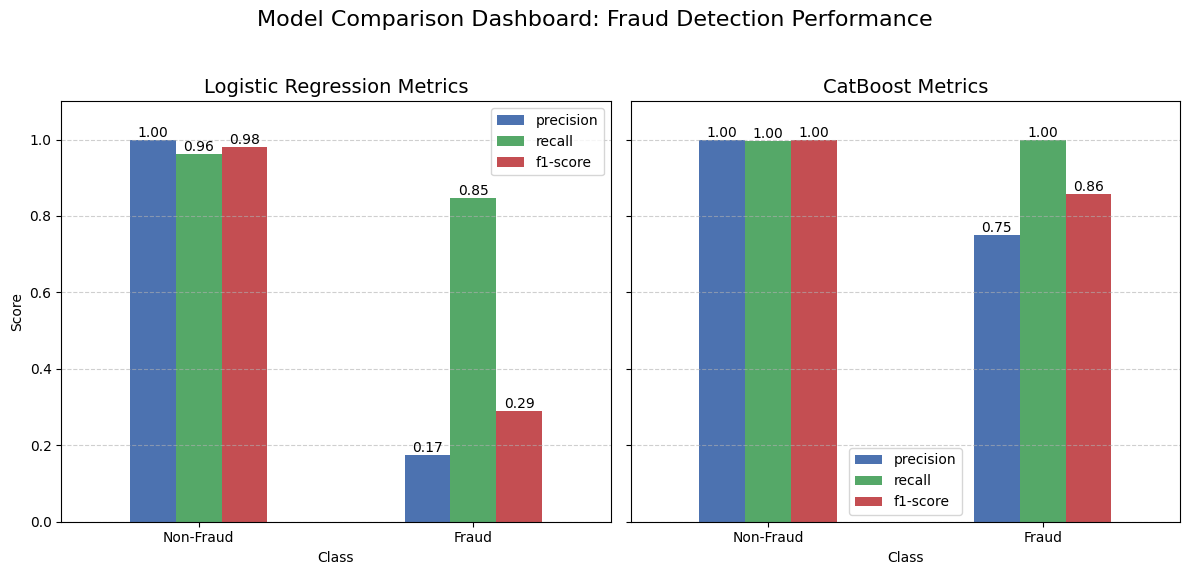

In [20]:
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.impute import SimpleImputer
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Handle Missing Values
# ============================================================

imputer = SimpleImputer(strategy='median')

# Fit imputer only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply same imputer to testing data
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 2. Define Three Machine Learning Models
# ============================================================

models_to_compare = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='Accuracy',
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
}


# ============================================================
# 3. Train and Evaluate All Three Models
# ============================================================

model_performance = {}
model_predictions = {}
confusion_matrices = {}

for name, clf in models_to_compare.items():

    print("\n" + "=" * 60)
    print(f"Training {name}")
    print("=" * 60)

    # Train model
    clf.fit(X_train_imputed, y_train)

    # Prediction
    y_pred = clf.predict(X_test_imputed)

    # Convert CatBoost prediction shape if necessary
    y_pred = y_pred.ravel()

    # Store predictions
    model_predictions[name] = y_pred

    # Classification report
    report = classification_report(
        y_test,
        y_pred,
        target_names=['Non-Fraud', 'Fraud'],
        output_dict=True
    )

    # Store precision, recall and F1
    model_performance[name] = pd.DataFrame(report).transpose().iloc[:2, :3]

    # Store confusion matrix
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    # Print results
    print(f"\n--- {name} Testing Report ---")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['Non-Fraud', 'Fraud']
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrices[name])

    print(
        f"Accuracy: "
        f"{accuracy_score(y_test, y_pred):.4f}"
    )


# ============================================================
# 4. Create Model Comparison Dashboard
# ============================================================

fig, axes = plt.subplots(
    1,
    len(models_to_compare),
    figsize=(6 * len(models_to_compare), 6),
    sharey=True
)

colors = ['#4C72B0', '#55A868', '#C44E52']

for i, (name, df_metrics) in enumerate(model_performance.items()):

    df_metrics.plot(
        kind='bar',
        ax=axes[i],
        color=colors,
        rot=0
    )

    axes[i].set_title(
        f'{name} Metrics',
        fontsize=14
    )

    axes[i].set_ylim(0, 1.1)

    axes[i].set_xlabel("Class")

    axes[i].set_ylabel("Score")

    axes[i].grid(
        axis='y',
        linestyle='--',
        alpha=0.6
    )

    # Add value labels
    for p in axes[i].patches:

        axes[i].annotate(
            f'{p.get_height():.2f}',
            (
                p.get_x() + p.get_width() / 2.,
                p.get_height()
            ),
            ha='center',
            va='center',
            xytext=(0, 5),
            textcoords='offset points'
        )


plt.suptitle(
    'Model Comparison Dashboard: Fraud Detection Performance',
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.95]
)

plt.show()


Training Logistic Regression

--- Logistic Regression Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      0.96      0.98      4019
       Fraud       0.17      0.85      0.29        39

    accuracy                           0.96      4058
   macro avg       0.59      0.90      0.63      4058
weighted avg       0.99      0.96      0.97      4058

Confusion Matrix:
[[3863  156]
 [   6   33]]
Accuracy: 0.9601

Training CatBoost

--- CatBoost Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00      4019
       Fraud       0.75      1.00      0.86        39

    accuracy                           1.00      4058
   macro avg       0.88      1.00      0.93      4058
weighted avg       1.00      1.00      1.00      4058

Confusion Matrix:
[[4006   13]
 [   0   39]]
Accuracy: 0.9968


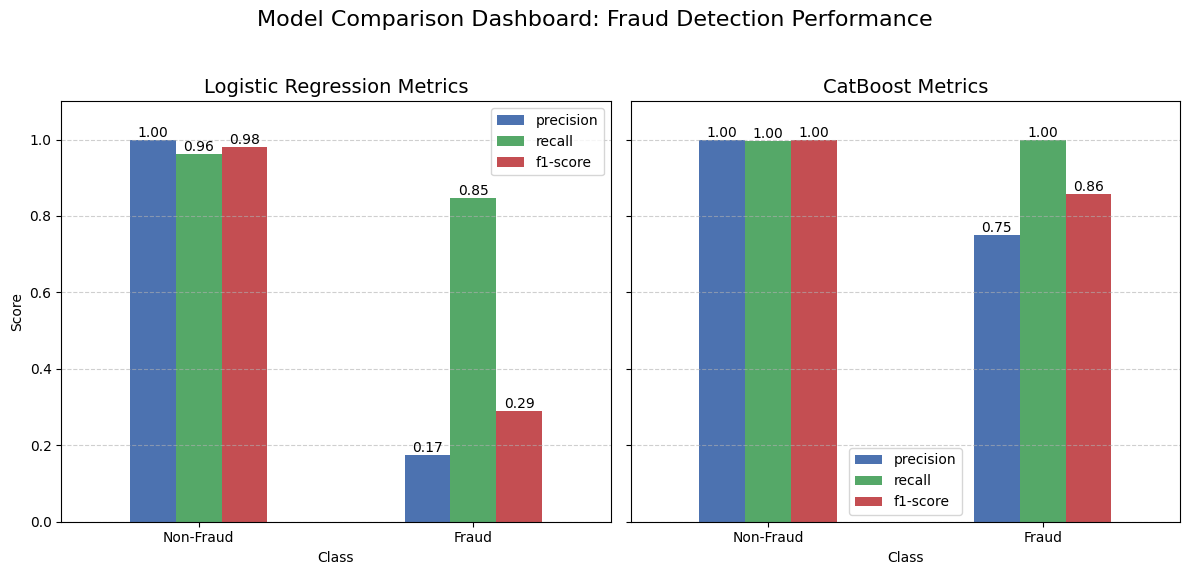

In [21]:
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.impute import SimpleImputer
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Handle Missing Values
# ============================================================

imputer = SimpleImputer(strategy='median')

# Fit imputer only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply same imputer to testing data
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 2. Define Three Machine Learning Models
# ============================================================

models_to_compare = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='Accuracy',
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
}


# ============================================================
# 3. Train and Evaluate All Three Models
# ============================================================

model_performance = {}
model_predictions = {}
confusion_matrices = {}

for name, clf in models_to_compare.items():

    print("\n" + "=" * 60)
    print(f"Training {name}")
    print("=" * 60)

    # Train model
    clf.fit(X_train_imputed, y_train)

    # Prediction
    y_pred = clf.predict(X_test_imputed)

    # Convert CatBoost prediction shape if necessary
    y_pred = y_pred.ravel()

    # Store predictions
    model_predictions[name] = y_pred

    # Classification report
    report = classification_report(
        y_test,
        y_pred,
        target_names=['Non-Fraud', 'Fraud'],
        output_dict=True
    )

    # Store precision, recall and F1
    model_performance[name] = pd.DataFrame(report).transpose().iloc[:2, :3]

    # Store confusion matrix
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    # Print results
    print(f"\n--- {name} Testing Report ---")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['Non-Fraud', 'Fraud']
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrices[name])

    print(
        f"Accuracy: "
        f"{accuracy_score(y_test, y_pred):.4f}"
    )


# ============================================================
# 4. Create Model Comparison Dashboard
# ============================================================

fig, axes = plt.subplots(
    1,
    len(models_to_compare),
    figsize=(6 * len(models_to_compare), 6),
    sharey=True
)

colors = ['#4C72B0', '#55A868', '#C44E52']

for i, (name, df_metrics) in enumerate(model_performance.items()):

    df_metrics.plot(
        kind='bar',
        ax=axes[i],
        color=colors,
        rot=0
    )

    axes[i].set_title(
        f'{name} Metrics',
        fontsize=14
    )

    axes[i].set_ylim(0, 1.1)

    axes[i].set_xlabel("Class")

    axes[i].set_ylabel("Score")

    axes[i].grid(
        axis='y',
        linestyle='--',
        alpha=0.6
    )

    # Add value labels
    for p in axes[i].patches:

        axes[i].annotate(
            f'{p.get_height():.2f}',
            (
                p.get_x() + p.get_width() / 2.,
                p.get_height()
            ),
            ha='center',
            va='center',
            xytext=(0, 5),
            textcoords='offset points'
        )


plt.suptitle(
    'Model Comparison Dashboard: Fraud Detection Performance',
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.95]
)

plt.show()


Training Logistic Regression

--- Logistic Regression Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      0.96      0.98      4019
       Fraud       0.17      0.85      0.29        39

    accuracy                           0.96      4058
   macro avg       0.59      0.90      0.63      4058
weighted avg       0.99      0.96      0.97      4058

Confusion Matrix:
[[3863  156]
 [   6   33]]
Accuracy: 0.9601

Training CatBoost

--- CatBoost Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00      4019
       Fraud       0.75      1.00      0.86        39

    accuracy                           1.00      4058
   macro avg       0.88      1.00      0.93      4058
weighted avg       1.00      1.00      1.00      4058

Confusion Matrix:
[[4006   13]
 [   0   39]]
Accuracy: 0.9968


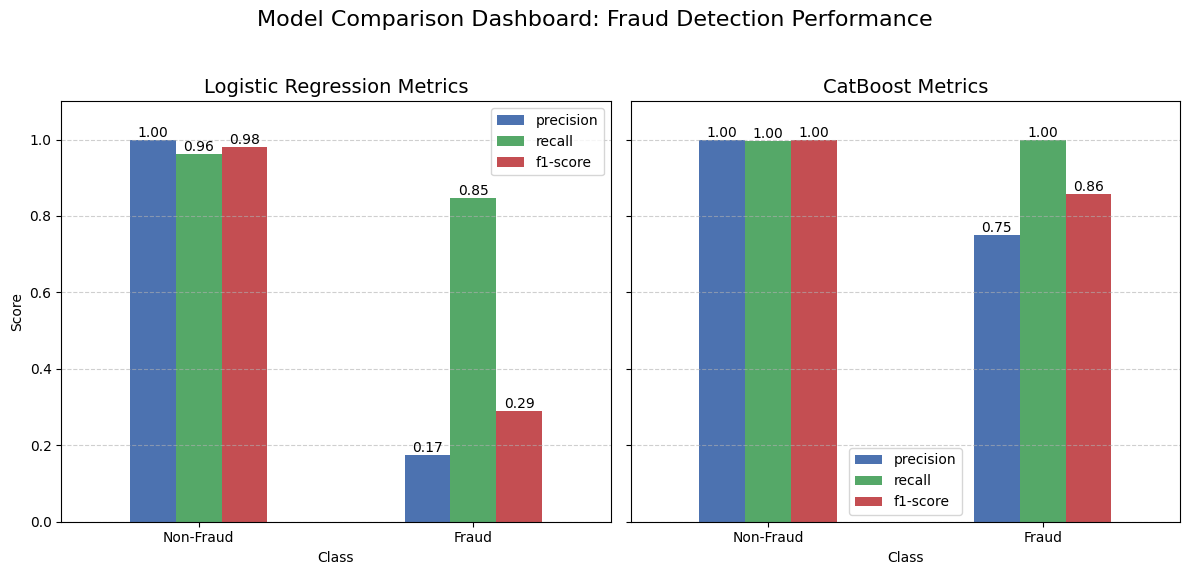

In [22]:
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.impute import SimpleImputer
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Handle Missing Values
# ============================================================

imputer = SimpleImputer(strategy='median')

# Fit imputer only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply same imputer to testing data
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 2. Define Three Machine Learning Models
# ============================================================

models_to_compare = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='Accuracy',
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
}


# ============================================================
# 3. Train and Evaluate All Three Models
# ============================================================

model_performance = {}
model_predictions = {}
confusion_matrices = {}

for name, clf in models_to_compare.items():

    print("\n" + "=" * 60)
    print(f"Training {name}")
    print("=" * 60)

    # Train model
    clf.fit(X_train_imputed, y_train)

    # Prediction
    y_pred = clf.predict(X_test_imputed)

    # Convert CatBoost prediction shape if necessary
    y_pred = y_pred.ravel()

    # Store predictions
    model_predictions[name] = y_pred

    # Classification report
    report = classification_report(
        y_test,
        y_pred,
        target_names=['Non-Fraud', 'Fraud'],
        output_dict=True
    )

    # Store precision, recall and F1
    model_performance[name] = pd.DataFrame(report).transpose().iloc[:2, :3]

    # Store confusion matrix
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    # Print results
    print(f"\n--- {name} Testing Report ---")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['Non-Fraud', 'Fraud']
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrices[name])

    print(
        f"Accuracy: "
        f"{accuracy_score(y_test, y_pred):.4f}"
    )


# ============================================================
# 4. Create Model Comparison Dashboard
# ============================================================

fig, axes = plt.subplots(
    1,
    len(models_to_compare),
    figsize=(6 * len(models_to_compare), 6),
    sharey=True
)

colors = ['#4C72B0', '#55A868', '#C44E52']

for i, (name, df_metrics) in enumerate(model_performance.items()):

    df_metrics.plot(
        kind='bar',
        ax=axes[i],
        color=colors,
        rot=0
    )

    axes[i].set_title(
        f'{name} Metrics',
        fontsize=14
    )

    axes[i].set_ylim(0, 1.1)

    axes[i].set_xlabel("Class")

    axes[i].set_ylabel("Score")

    axes[i].grid(
        axis='y',
        linestyle='--',
        alpha=0.6
    )

    # Add value labels
    for p in axes[i].patches:

        axes[i].annotate(
            f'{p.get_height():.2f}',
            (
                p.get_x() + p.get_width() / 2.,
                p.get_height()
            ),
            ha='center',
            va='center',
            xytext=(0, 5),
            textcoords='offset points'
        )


plt.suptitle(
    'Model Comparison Dashboard: Fraud Detection Performance',
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.95]
)

plt.show()


Training Logistic Regression

--- Logistic Regression Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      0.96      0.98      4019
       Fraud       0.17      0.85      0.29        39

    accuracy                           0.96      4058
   macro avg       0.59      0.90      0.63      4058
weighted avg       0.99      0.96      0.97      4058

Confusion Matrix:
[[3863  156]
 [   6   33]]
Accuracy: 0.9601

Training CatBoost

--- CatBoost Testing Report ---
              precision    recall  f1-score   support

   Non-Fraud       1.00      1.00      1.00      4019
       Fraud       0.75      1.00      0.86        39

    accuracy                           1.00      4058
   macro avg       0.88      1.00      0.93      4058
weighted avg       1.00      1.00      1.00      4058

Confusion Matrix:
[[4006   13]
 [   0   39]]
Accuracy: 0.9968


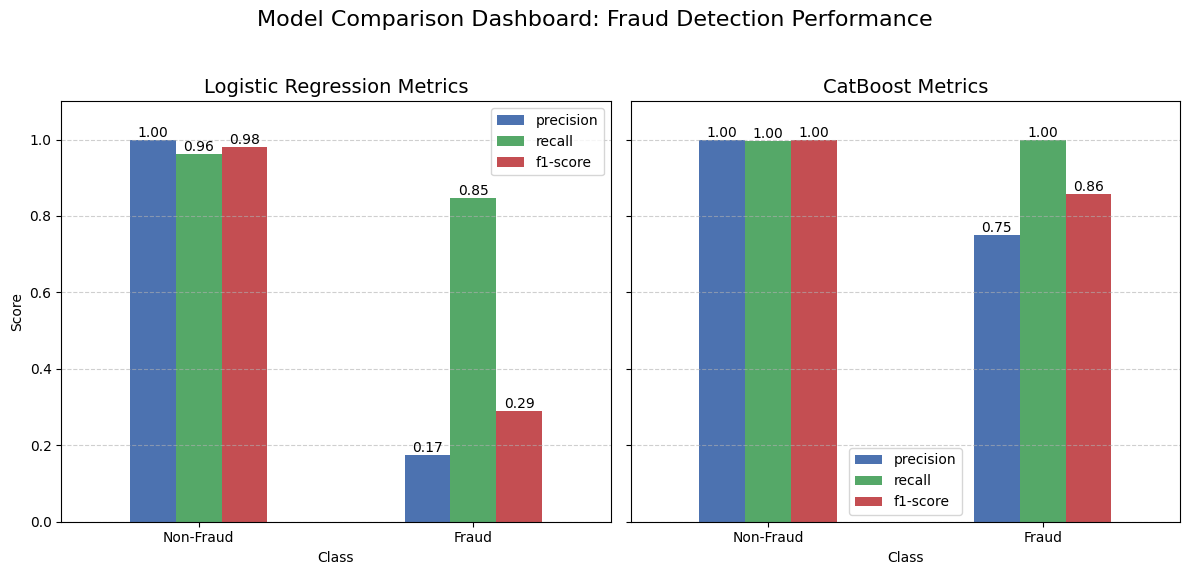

In [23]:
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

from sklearn.impute import SimpleImputer
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Handle Missing Values
# ============================================================

imputer = SimpleImputer(strategy='median')

# Fit imputer only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply same imputer to testing data
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 2. Define Three Machine Learning Models
# ============================================================

models_to_compare = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='Accuracy',
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
}


# ============================================================
# 3. Train and Evaluate All Three Models
# ============================================================

model_performance = {}
model_predictions = {}
confusion_matrices = {}

for name, clf in models_to_compare.items():

    print("\n" + "=" * 60)
    print(f"Training {name}")
    print("=" * 60)

    # Train model
    clf.fit(X_train_imputed, y_train)

    # Prediction
    y_pred = clf.predict(X_test_imputed)

    # Convert CatBoost prediction shape if necessary
    y_pred = y_pred.ravel()

    # Store predictions
    model_predictions[name] = y_pred

    # Classification report
    report = classification_report(
        y_test,
        y_pred,
        target_names=['Non-Fraud', 'Fraud'],
        output_dict=True
    )

    # Store precision, recall and F1
    model_performance[name] = pd.DataFrame(report).transpose().iloc[:2, :3]

    # Store confusion matrix
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    # Print results
    print(f"\n--- {name} Testing Report ---")

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['Non-Fraud', 'Fraud']
        )
    )

    print("Confusion Matrix:")
    print(confusion_matrices[name])

    print(
        f"Accuracy: "
        f"{accuracy_score(y_test, y_pred):.4f}"
    )


# ============================================================
# 4. Create Model Comparison Dashboard
# ============================================================

fig, axes = plt.subplots(
    1,
    len(models_to_compare),
    figsize=(6 * len(models_to_compare), 6),
    sharey=True
)

colors = ['#4C72B0', '#55A868', '#C44E52']

for i, (name, df_metrics) in enumerate(model_performance.items()):

    df_metrics.plot(
        kind='bar',
        ax=axes[i],
        color=colors,
        rot=0
    )

    axes[i].set_title(
        f'{name} Metrics',
        fontsize=14
    )

    axes[i].set_ylim(0, 1.1)

    axes[i].set_xlabel("Class")

    axes[i].set_ylabel("Score")

    axes[i].grid(
        axis='y',
        linestyle='--',
        alpha=0.6
    )

    # Add value labels
    for p in axes[i].patches:

        axes[i].annotate(
            f'{p.get_height():.2f}',
            (
                p.get_x() + p.get_width() / 2.,
                p.get_height()
            ),
            ha='center',
            va='center',
            xytext=(0, 5),
            textcoords='offset points'
        )


plt.suptitle(
    'Model Comparison Dashboard: Fraud Detection Performance',
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0.03, 1, 0.95]
)

plt.show()

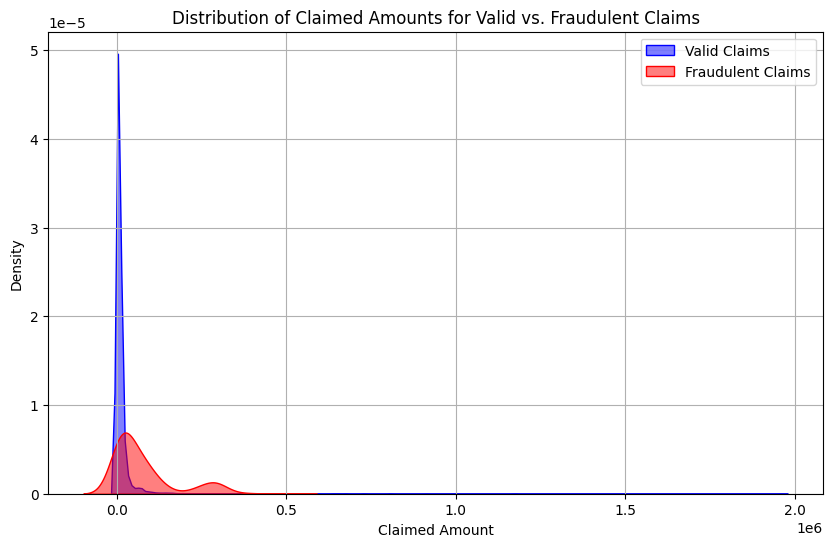

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter data for fraudulent and non-fraudulent claims
valid_claims = df[df['FRAUD_FLAG'] == 0]
fraud_claims = df[df['FRAUD_FLAG'] == 1]

plt.figure(figsize=(10, 6))
sns.kdeplot(valid_claims['CLAIMED'], label='Valid Claims', fill=True, color='blue', alpha=0.5)
sns.kdeplot(fraud_claims['CLAIMED'], label='Fraudulent Claims', fill=True, color='red', alpha=0.5)

plt.title('Distribution of Claimed Amounts for Valid vs. Fraudulent Claims')
plt.xlabel('Claimed Amount')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

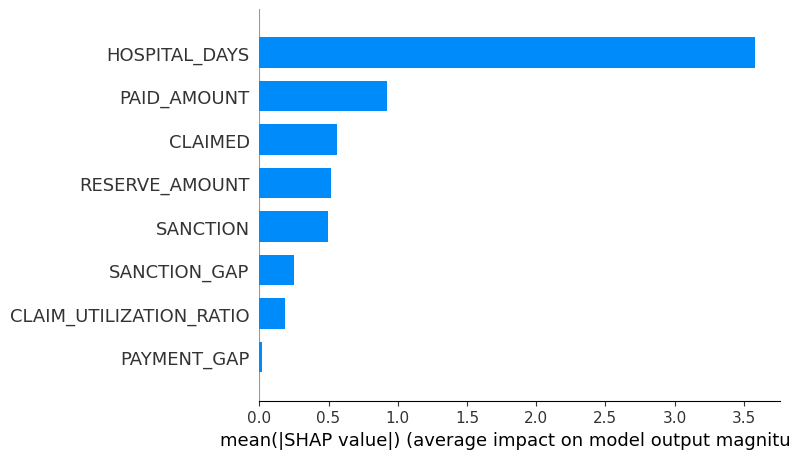

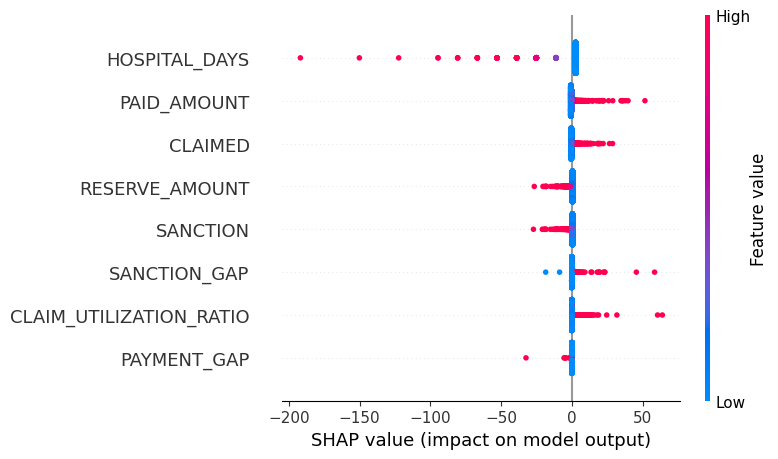

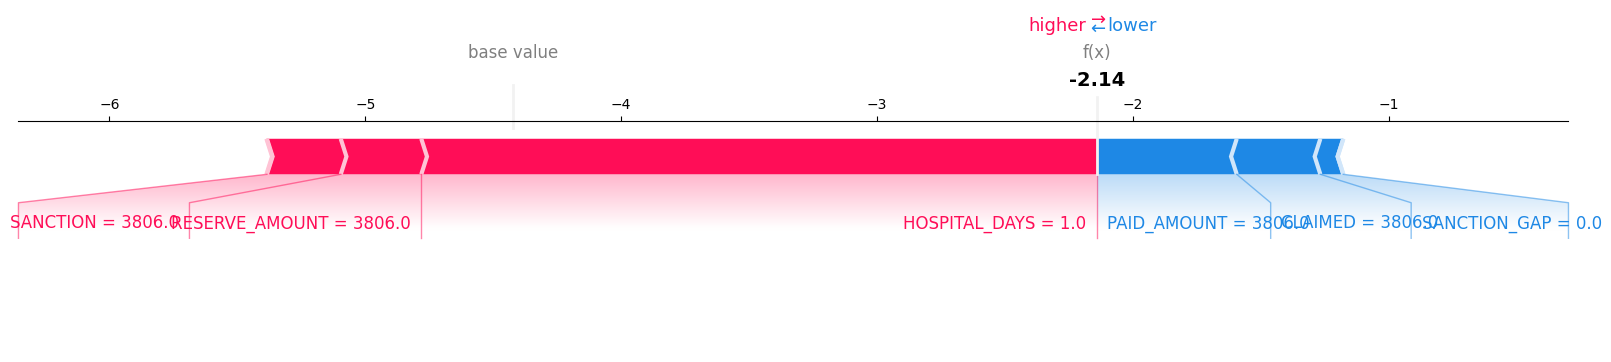

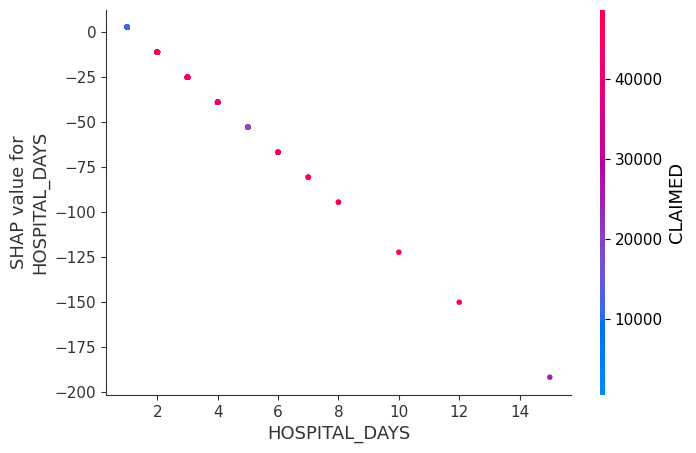

In [25]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

# 1. Ensure data is imputed and model is assigned
# Re-run imputer for test set consistency
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Get the trained Logistic Regression model from our comparison dict
# We must ensure it is fit before explaining
lr_model = models_to_compare['Logistic Regression']
lr_model.fit(X_train_imputed, y_train)

# 2. Initialize SHAP LinearExplainer
explainer = shap.LinearExplainer(lr_model, X_train_imputed)

# Compute SHAP values for test dataset
shap_values = explainer.shap_values(X_test_imputed)

# Select SHAP values for the "Fraud" class (class 1)
# LinearExplainer output shape can vary by shap version; handling standard 2D array case
shap_values_class_1 = shap_values
expected_value = explainer.expected_value

# -------------------------------
# Global Explainability
# -------------------------------

# Global feature importance (bar plot)
plt.figure()
shap.summary_plot(
    shap_values_class_1,
    X_test_imputed,
    feature_names=features,
    plot_type="bar",
    show=False
)
plt.show()

# Detailed global impact visualization
plt.figure()
shap.summary_plot(
    shap_values_class_1,
    X_test_imputed,
    feature_names=features,
    show=False
)
plt.show()

# -------------------------------
# Local Explainability
# -------------------------------

# Explain an individual claim prediction
claim_index = 0

shap.force_plot(
    expected_value,
    shap_values_class_1[claim_index],
    X_test_imputed[claim_index],
    feature_names=features,
    matplotlib=True
)

# -------------------------------
# Feature Interaction Analysis
# -------------------------------

# Dependence plot for the most important feature (Hospital Days is index 4)
shap.dependence_plot(
    "HOSPITAL_DAYS",
    shap_values_class_1,
    X_test_imputed,
    feature_names=features
)

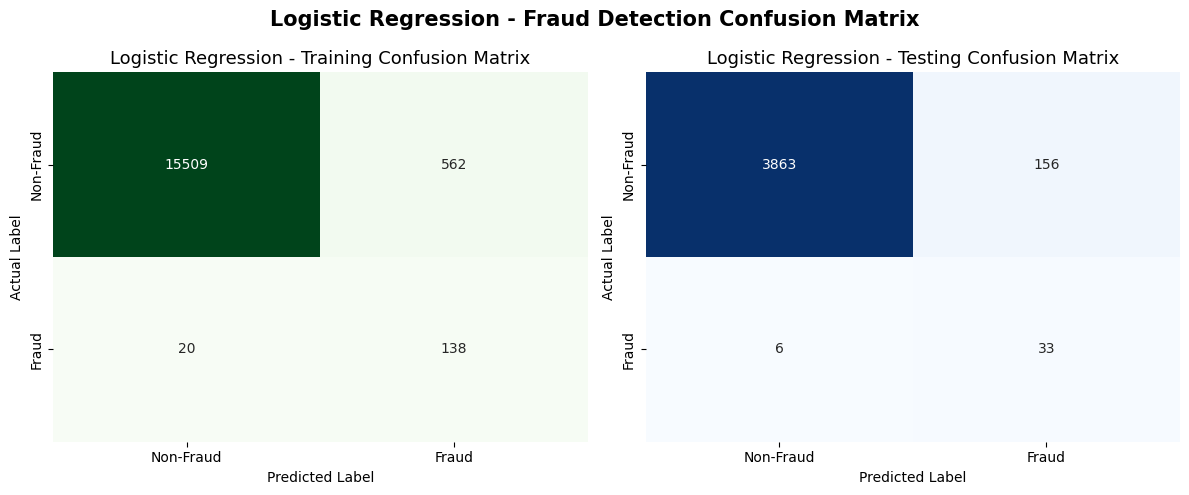

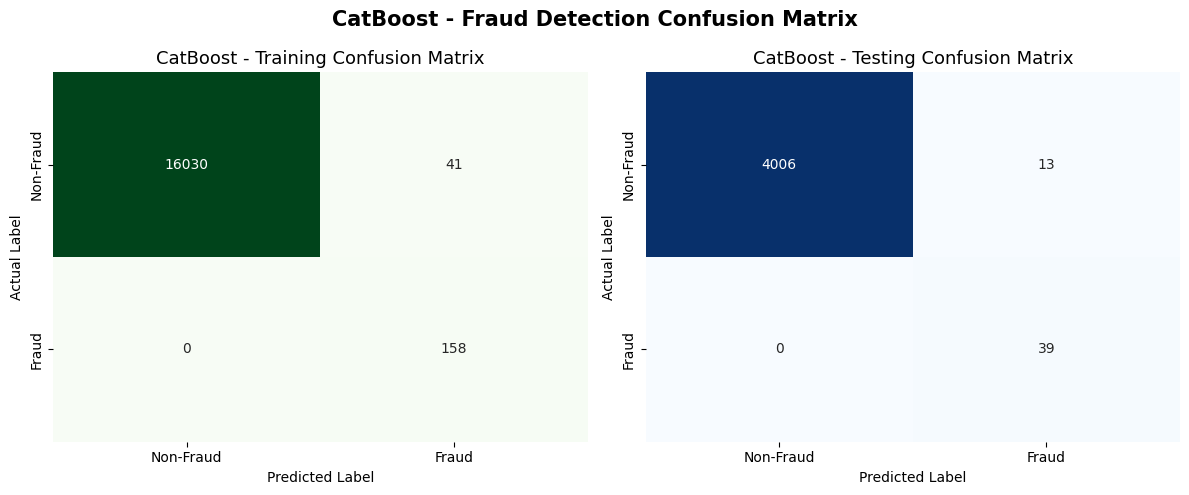

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier

from sklearn.metrics import confusion_matrix
from sklearn.impute import SimpleImputer


# ============================================================
# 1. PREPARE DATA
# ============================================================

# Handle missing values
imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 2. DEFINE THREE MODELS
# ============================================================

models_to_compare = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
}


# ============================================================
# 3. TRAIN MODELS + CONFUSION MATRICES
# ============================================================

for name, clf in models_to_compare.items():

    # Train model
    clf.fit(X_train_imputed, y_train)

    # Training prediction
    y_train_pred = clf.predict(X_train_imputed)

    # Testing prediction
    y_test_pred = clf.predict(X_test_imputed)

    # Convert predictions to 1D
    y_train_pred = y_train_pred.ravel()
    y_test_pred = y_test_pred.ravel()


    # ========================================================
    # Calculate Confusion Matrices
    # ========================================================

    cm_train = confusion_matrix(
        y_train,
        y_train_pred
    )

    cm_test = confusion_matrix(
        y_test,
        y_test_pred
    )


    # ========================================================
    # Create Training + Testing Graph
    # ========================================================

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 5)
    )


    # ========================================================
    # Training Confusion Matrix
    # ========================================================

    sns.heatmap(
        cm_train,
        annot=True,
        fmt='d',
        cmap='Greens',
        cbar=False,
        xticklabels=['Non-Fraud', 'Fraud'],
        yticklabels=['Non-Fraud', 'Fraud'],
        ax=axes[0]
    )

    axes[0].set_title(
        f'{name} - Training Confusion Matrix',
        fontsize=13
    )

    axes[0].set_xlabel(
        'Predicted Label'
    )

    axes[0].set_ylabel(
        'Actual Label'
    )


    # ========================================================
    # Testing Confusion Matrix
    # ========================================================

    sns.heatmap(
        cm_test,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['Non-Fraud', 'Fraud'],
        yticklabels=['Non-Fraud', 'Fraud'],
        ax=axes[1]
    )

    axes[1].set_title(
        f'{name} - Testing Confusion Matrix',
        fontsize=13
    )

    axes[1].set_xlabel(
        'Predicted Label'
    )

    axes[1].set_ylabel(
        'Actual Label'
    )


    # ========================================================
    # Display
    # ========================================================

    plt.suptitle(
        f'{name} - Fraud Detection Confusion Matrix',
        fontsize=15,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()

In [27]:
from sklearn.metrics import classification_report, accuracy_score

# ============================================================
# CLASSIFICATION REPORT FOR ALL THREE ALGORITHMS
# ============================================================

for name, clf in models_to_compare.items():

    print("\n" + "=" * 70)
    print(f"                 {name}")
    print("=" * 70)


    # ========================================================
    # 1. TRAINING PREDICTIONS
    # ========================================================

    train_preds = clf.predict(X_train_imputed)

    # CatBoost may return a 2D array, so convert to 1D
    train_preds = train_preds.ravel()

    train_accuracy = accuracy_score(
        y_train,
        train_preds
    )

    print("\n--- Training Classification Report ---")

    print(
        classification_report(
            y_train,
            train_preds,
            target_names=['Non-Fraud', 'Fraud'],
            digits=4
        )
    )

    print(
        f"Training Accuracy: {train_accuracy * 100:.2f}%"
    )


    # ========================================================
    # 2. TESTING PREDICTIONS
    # ========================================================

    test_preds = clf.predict(X_test_imputed)

    # CatBoost may return a 2D array, so convert to 1D
    test_preds = test_preds.ravel()

    test_accuracy = accuracy_score(
        y_test,
        test_preds
    )

    print("\n--- Testing Classification Report ---")

    print(
        classification_report(
            y_test,
            test_preds,
            target_names=['Non-Fraud', 'Fraud'],
            digits=4
        )
    )

    print(
        f"Testing Accuracy: {test_accuracy * 100:.2f}%"
    )


                 Logistic Regression

--- Training Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     0.9987    0.9650    0.9816     16071
       Fraud     0.1971    0.8734    0.3217       158

    accuracy                         0.9641     16229
   macro avg     0.5979    0.9192    0.6516     16229
weighted avg     0.9909    0.9641    0.9752     16229

Training Accuracy: 96.41%

--- Testing Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     0.9984    0.9612    0.9795      4019
       Fraud     0.1746    0.8462    0.2895        39

    accuracy                         0.9601      4058
   macro avg     0.5865    0.9037    0.6345      4058
weighted avg     0.9905    0.9601    0.9728      4058

Testing Accuracy: 96.01%

                 CatBoost

--- Training Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     1.0000    0.9974    0.9987     16071
  

In [28]:
from sklearn.metrics import classification_report, accuracy_score

# ============================================================
# CLASSIFICATION REPORT FOR ALL THREE ALGORITHMS
# ============================================================

for name, clf in models_to_compare.items():

    print("\n" + "=" * 70)
    print(f"                 {name}")
    print("=" * 70)


    # ========================================================
    # 1. TRAINING PREDICTIONS
    # ========================================================

    train_preds = clf.predict(X_train_imputed)

    # CatBoost may return a 2D array, so convert to 1D
    train_preds = train_preds.ravel()

    train_accuracy = accuracy_score(
        y_train,
        train_preds
    )

    print("\n--- Training Classification Report ---")

    print(
        classification_report(
            y_train,
            train_preds,
            target_names=['Non-Fraud', 'Fraud'],
            digits=4
        )
    )

    print(
        f"Training Accuracy: {train_accuracy * 100:.2f}%"
    )


    # ========================================================
    # 2. TESTING PREDICTIONS
    # ========================================================

    test_preds = clf.predict(X_test_imputed)

    # CatBoost may return a 2D array, so convert to 1D
    test_preds = test_preds.ravel()

    test_accuracy = accuracy_score(
        y_test,
        test_preds
    )

    print("\n--- Testing Classification Report ---")

    print(
        classification_report(
            y_test,
            test_preds,
            target_names=['Non-Fraud', 'Fraud'],
            digits=4
        )
    )

    print(
        f"Testing Accuracy: {test_accuracy * 100:.2f}%"
    )


                 Logistic Regression

--- Training Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     0.9987    0.9650    0.9816     16071
       Fraud     0.1971    0.8734    0.3217       158

    accuracy                         0.9641     16229
   macro avg     0.5979    0.9192    0.6516     16229
weighted avg     0.9909    0.9641    0.9752     16229

Training Accuracy: 96.41%

--- Testing Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     0.9984    0.9612    0.9795      4019
       Fraud     0.1746    0.8462    0.2895        39

    accuracy                         0.9601      4058
   macro avg     0.5865    0.9037    0.6345      4058
weighted avg     0.9905    0.9601    0.9728      4058

Testing Accuracy: 96.01%

                 CatBoost

--- Training Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     1.0000    0.9974    0.9987     16071
  

In [29]:
from sklearn.metrics import classification_report, accuracy_score

# ============================================================
# CLASSIFICATION REPORT FOR ALL THREE ALGORITHMS
# ============================================================

for name, clf in models_to_compare.items():

    print("\n" + "=" * 70)
    print(f"                 {name}")
    print("=" * 70)


    # ========================================================
    # 1. TRAINING PREDICTIONS
    # ========================================================

    train_preds = clf.predict(X_train_imputed)

    # CatBoost may return a 2D array, so convert to 1D
    train_preds = train_preds.ravel()

    train_accuracy = accuracy_score(
        y_train,
        train_preds
    )

    print("\n--- Training Classification Report ---")

    print(
        classification_report(
            y_train,
            train_preds,
            target_names=['Non-Fraud', 'Fraud'],
            digits=4
        )
    )

    print(
        f"Training Accuracy: {train_accuracy * 100:.2f}%"
    )


    # ========================================================
    # 2. TESTING PREDICTIONS
    # ========================================================

    test_preds = clf.predict(X_test_imputed)

    # CatBoost may return a 2D array, so convert to 1D
    test_preds = test_preds.ravel()

    test_accuracy = accuracy_score(
        y_test,
        test_preds
    )

    print("\n--- Testing Classification Report ---")

    print(
        classification_report(
            y_test,
            test_preds,
            target_names=['Non-Fraud', 'Fraud'],
            digits=4
        )
    )

    print(
        f"Testing Accuracy: {test_accuracy * 100:.2f}%"
    )


                 Logistic Regression

--- Training Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     0.9987    0.9650    0.9816     16071
       Fraud     0.1971    0.8734    0.3217       158

    accuracy                         0.9641     16229
   macro avg     0.5979    0.9192    0.6516     16229
weighted avg     0.9909    0.9641    0.9752     16229

Training Accuracy: 96.41%

--- Testing Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     0.9984    0.9612    0.9795      4019
       Fraud     0.1746    0.8462    0.2895        39

    accuracy                         0.9601      4058
   macro avg     0.5865    0.9037    0.6345      4058
weighted avg     0.9905    0.9601    0.9728      4058

Testing Accuracy: 96.01%

                 CatBoost

--- Training Classification Report ---
              precision    recall  f1-score   support

   Non-Fraud     1.0000    0.9974    0.9987     16071
  

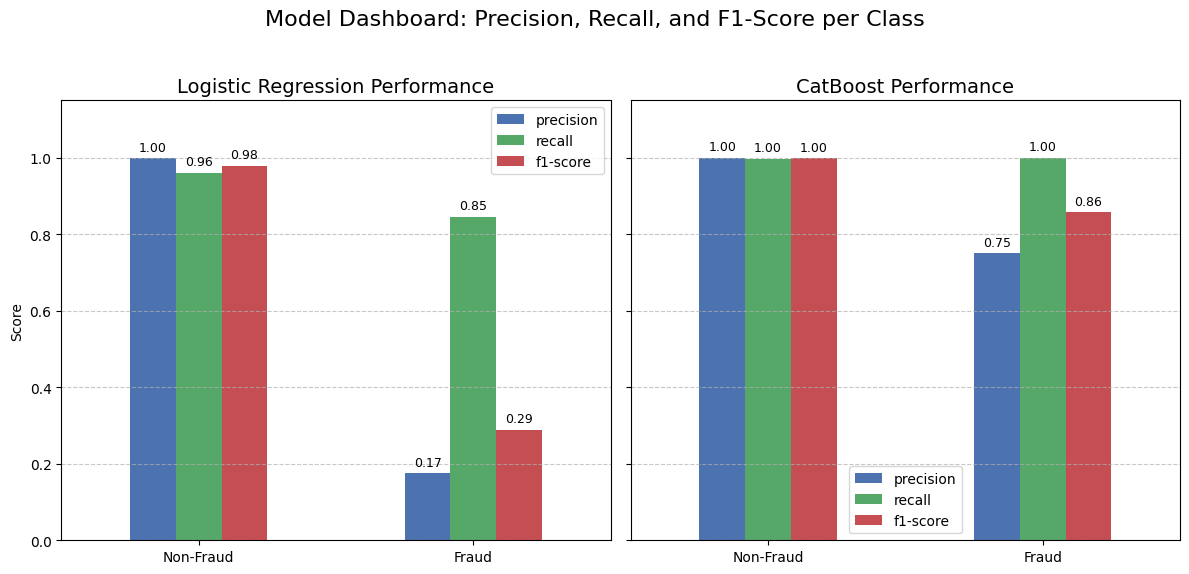

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

# Prepare to store results
model_reports = {}

# Generate reports for all models in the dictionary
for name, clf in models_to_compare.items():
    # Ensure the model is fitted before prediction
    clf.fit(X_train_imputed, y_train)

    test_preds = clf.predict(X_test_imputed)
    # CatBoost might return 2D array
    test_preds = test_preds.ravel()
    report = classification_report(y_test, test_preds, target_names=['Non-Fraud', 'Fraud'], output_dict=True)
    # Convert to a format suitable for plotting (just the class metrics)
    model_reports[name] = pd.DataFrame(report).transpose().iloc[:2, :3]

# Determine the number of models and set up the grid dynamically
num_models = len(model_reports)
fig, axes = plt.subplots(1, num_models, figsize=(6 * num_models, 6), sharey=True)

# Ensure axes is iterable even if there is only one model
if num_models == 1:
    axes = [axes]

colors = ['#4C72B0', '#55A868', '#C44E52']

for i, (name, df_metrics) in enumerate(model_reports.items()):
    df_metrics.plot(kind='bar', ax=axes[i], color=colors, rot=0)
    axes[i].set_title(f'{name} Performance', fontsize=14)
    axes[i].set_ylim(0, 1.15)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)
    axes[i].set_ylabel('Score')

    # Add value annotations on top of bars
    for p in axes[i].patches:
        axes[i].annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=9)

plt.suptitle('Model Dashboard: Precision, Recall, and F1-Score per Class', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Feature Selection Dashboard
This dashboard visualizes the predictive power of each feature. We use the absolute value of the coefficients from the Logistic Regression model to determine which variables contribute most to the fraud classification.

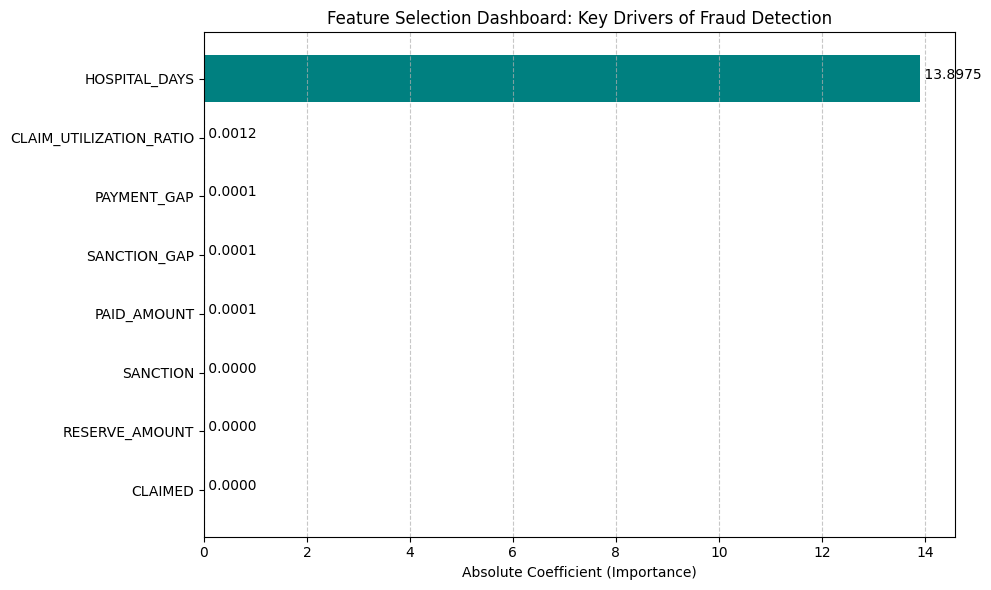

In [31]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Extract coefficients from Logistic Regression using the correct variable name
# The trained model is stored in the models_to_compare dictionary
lr_model = models_to_compare['Logistic Regression']

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': np.abs(lr_model.coef_[0])
})

# Sort by importance
feature_importance = feature_importance.sort_values(by='Importance', ascending=True)

# Create Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'], color='teal')
plt.xlabel('Absolute Coefficient (Importance)')
plt.title('Feature Selection Dashboard: Key Drivers of Fraud Detection')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add labels to bars
for index, value in enumerate(feature_importance['Importance']):
    plt.text(value, index, f' {value:.4f}')

plt.tight_layout()
plt.show()

In [32]:
feature_importance.to_csv('feature_importance.csv', index=False)
print("Feature importance successfully exported to 'feature_importance.csv'.")

Feature importance successfully exported to 'feature_importance.csv'.


### Precision-Recall Curve Comparison
For imbalanced datasets, the Precision-Recall (PR) curve is often more informative than the ROC curve because it ignores true negatives, focusing entirely on the performance of the minority class (Fraud).

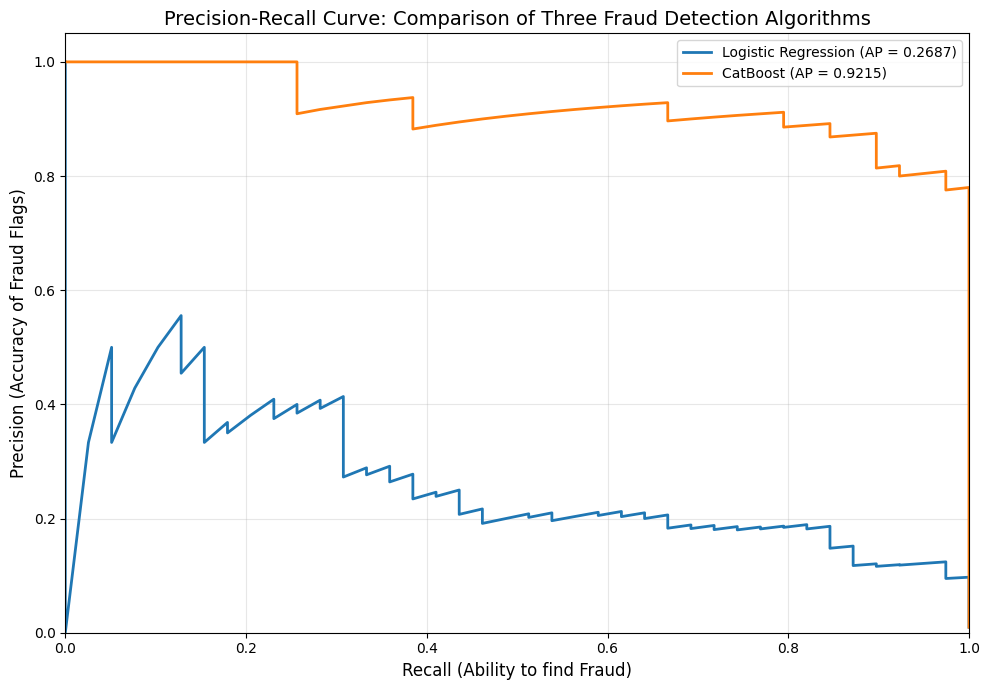

In [33]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt


# ============================================================
# PRECISION-RECALL CURVE FOR 3 ALGORITHMS
# ============================================================

plt.figure(figsize=(10, 7))


for name, clf in models_to_compare.items():

    # Get probability scores for Fraud class
    y_prob = clf.predict_proba(X_test_imputed)[:, 1]

    # Calculate Precision and Recall
    precision, recall, _ = precision_recall_curve(
        y_test,
        y_prob
    )

    # Calculate Average Precision (AP)
    ap_score = average_precision_score(
        y_test,
        y_prob
    )

    # Plot PR Curve
    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f'{name} (AP = {ap_score:.4f})'
    )


# ============================================================
# GRAPH SETTINGS
# ============================================================

plt.xlabel(
    'Recall (Ability to find Fraud)',
    fontsize=12
)

plt.ylabel(
    'Precision (Accuracy of Fraud Flags)',
    fontsize=12
)

plt.title(
    'Precision-Recall Curve: Comparison of Three Fraud Detection Algorithms',
    fontsize=14
)

plt.legend(
    loc='upper right',
    fontsize=10
)

plt.grid(
    alpha=0.3
)

plt.ylim(
    [0.0, 1.05]
)

plt.xlim(
    [0.0, 1.0]
)

plt.tight_layout()

plt.show()

### Correlation Heatmap: Identifying Fraud Indicators
This heatmap visualizes the Pearson correlation coefficient between our features and the `FRAUD_FLAG`. Values closer to 1 or -1 indicate a stronger relationship.

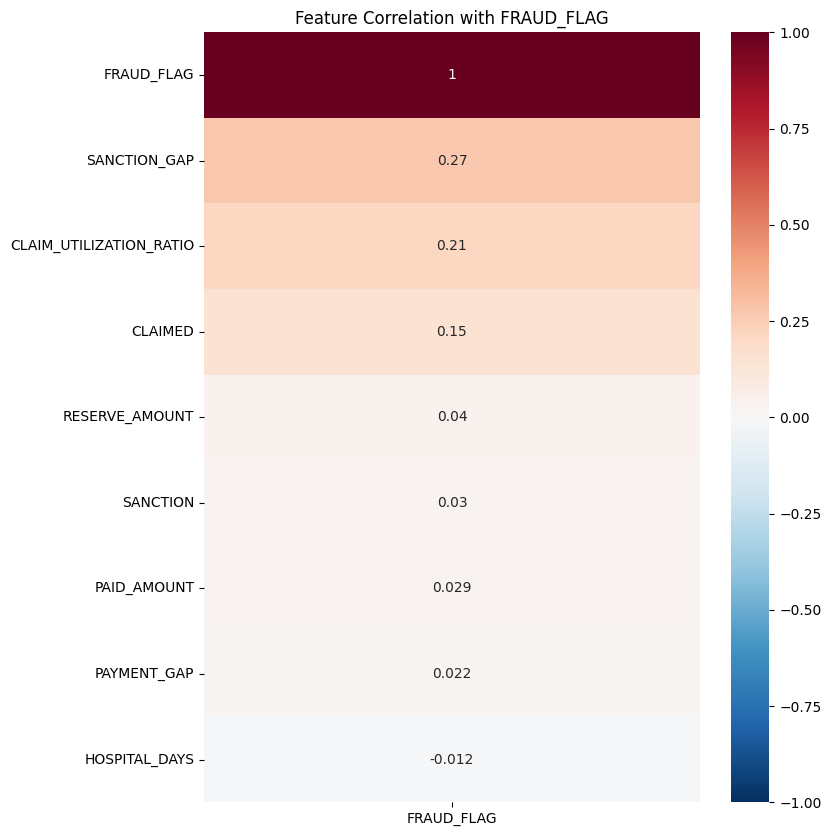

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation for the selected features and target
corr_features = features + ['FRAUD_FLAG']
correlation_data = df[corr_features].corr()

# Plotting the heatmap focusing on the Fraud Flag column
plt.figure(figsize=(8, 10))
sns.heatmap(correlation_data[['FRAUD_FLAG']].sort_values(by='FRAUD_FLAG', ascending=False),
            annot=True,
            cmap='RdBu_r',
            vmin=-1,
            vmax=1)

plt.title('Feature Correlation with FRAUD_FLAG')
plt.show()

### 5-Fold Cross-Validation
To robustly evaluate our models, we perform cross-validation. This involves splitting the data into 5 parts, training on 4 and testing on 1, repeating this 5 times. We use `StratifiedKFold` to maintain the class balance (Fraud vs. Non-Fraud) in each fold.

In [35]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

from catboost import CatBoostClassifier

import pandas as pd


# ============================================================
# 2. HANDLE MISSING VALUES
# ============================================================

imputer = SimpleImputer(strategy='median')

X_train_imputed = imputer.fit_transform(X_train)


# ============================================================
# 3. DEFINE THREE ALGORITHMS
# ============================================================

models_to_compare = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        verbose=0,
        random_seed=42,
        auto_class_weights='Balanced'
    )
}


# ============================================================
# 4. STRATIFIED 5-FOLD CROSS VALIDATION
# ============================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 5. METRICS
# ============================================================

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]


# ============================================================
# 6. RUN CROSS-VALIDATION FOR ALL THREE MODELS
# ============================================================

results = {}

for name, clf in models_to_compare.items():

    print("\n" + "=" * 70)
    print(f"Running 5-Fold Cross-Validation: {name}")
    print("=" * 70)

    cv_results = cross_validate(
        clf,
        X_train_imputed,
        y_train,
        cv=skf,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    results[name] = cv_results


# ============================================================
# 7. DISPLAY RESULTS
# ============================================================

for name, metrics in results.items():

    print("\n" + "-" * 60)
    print(f"{name} Cross-Validation Results (5 Folds)")
    print("-" * 60)

    print(
        f"Mean Accuracy:  "
        f"{metrics['test_accuracy'].mean():.4f} "
        f"(+/- {metrics['test_accuracy'].std():.4f})"
    )

    print(
        f"Mean Precision: "
        f"{metrics['test_precision'].mean():.4f} "
        f"(+/- {metrics['test_precision'].std():.4f})"
    )

    print(
        f"Mean Recall:    "
        f"{metrics['test_recall'].mean():.4f} "
        f"(+/- {metrics['test_recall'].std():.4f})"
    )

    print(
        f"Mean F1-Score:  "
        f"{metrics['test_f1'].mean():.4f} "
        f"(+/- {metrics['test_f1'].std():.4f})"
    )

    print(
        f"Mean ROC-AUC:   "
        f"{metrics['test_roc_auc'].mean():.4f} "
        f"(+/- {metrics['test_roc_auc'].std():.4f})"
    )



Running 5-Fold Cross-Validation: Logistic Regression

Running 5-Fold Cross-Validation: CatBoost

------------------------------------------------------------
Logistic Regression Cross-Validation Results (5 Folds)
------------------------------------------------------------
Mean Accuracy:  0.9640 (+/- 0.0033)
Mean Precision: 0.1967 (+/- 0.0139)
Mean Recall:    0.8673 (+/- 0.0533)
Mean F1-Score:  0.3202 (+/- 0.0174)
Mean ROC-AUC:   0.9766 (+/- 0.0136)

------------------------------------------------------------
CatBoost Cross-Validation Results (5 Folds)
------------------------------------------------------------
Mean Accuracy:  0.9969 (+/- 0.0006)
Mean Precision: 0.7662 (+/- 0.0370)
Mean Recall:    0.9875 (+/- 0.0250)
Mean F1-Score:  0.8622 (+/- 0.0254)
Mean ROC-AUC:   0.9993 (+/- 0.0002)


### Model Retraining & Multi-Metric Comparison
We are comparing CatBoost and Logistic Regression using all available features to identify the best balance between catching fraud (Recall) and minimizing false alarms (Precision).


                 Logistic Regression
Training Accuracy : 96.41%
Testing Accuracy  : 96.01%


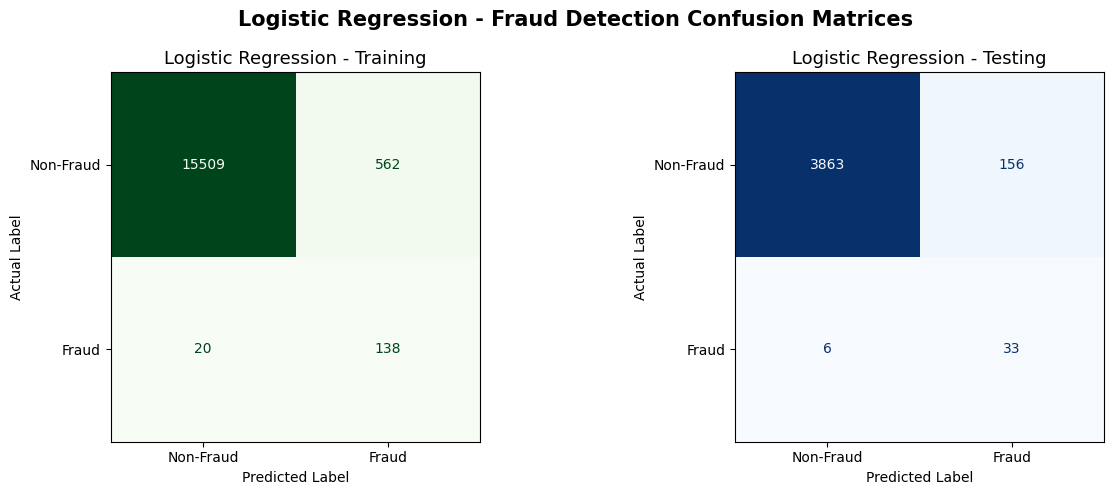


Logistic Regression - Testing Classification Report
              precision    recall  f1-score   support

   Non-Fraud     0.9984    0.9612    0.9795      4019
       Fraud     0.1746    0.8462    0.2895        39

    accuracy                         0.9601      4058
   macro avg     0.5865    0.9037    0.6345      4058
weighted avg     0.9905    0.9601    0.9728      4058


                 CatBoost
Training Accuracy : 99.75%
Testing Accuracy  : 99.68%


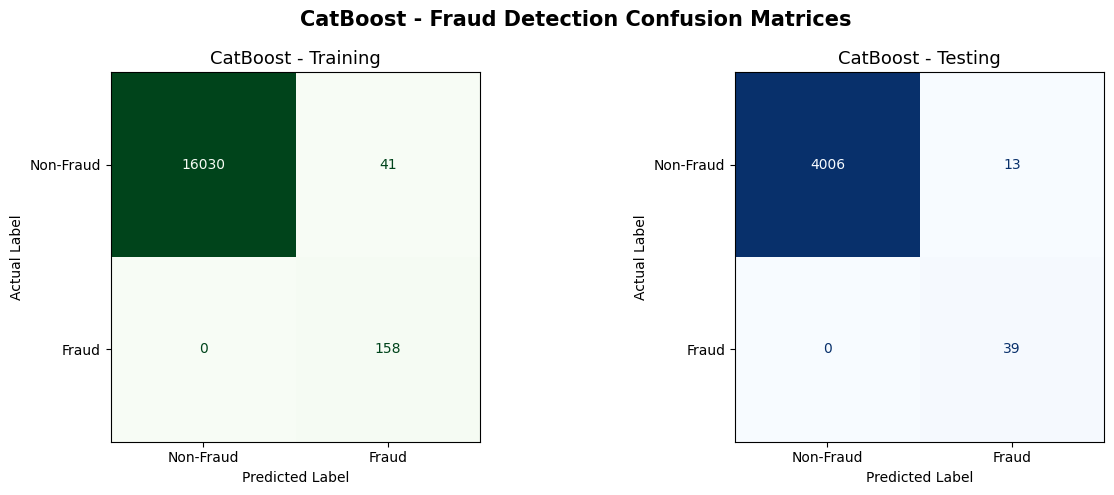


CatBoost - Testing Classification Report
              precision    recall  f1-score   support

   Non-Fraud     1.0000    0.9968    0.9984      4019
       Fraud     0.7500    1.0000    0.8571        39

    accuracy                         0.9968      4058
   macro avg     0.8750    0.9984    0.9278      4058
weighted avg     0.9976    0.9968    0.9970      4058



FINAL MODEL COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,96.01%,17.46%,84.62%,28.95%
1,CatBoost,99.68%,75.00%,100.00%,85.71%


In [36]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

from catboost import CatBoostClassifier


# ============================================================
# 1. HANDLE MISSING VALUES
# ============================================================

imputer = SimpleImputer(strategy='median')

# Fit ONLY on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply same transformation to test data
X_test_imputed = imputer.transform(X_test)


# ============================================================
# 2. DEFINE THREE ALGORITHMS
# ============================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    "CatBoost": CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        verbose=0,
        auto_class_weights='Balanced',
        random_seed=42
    )
}


# ============================================================
# 3. TRAIN + CONFUSION MATRIX
# ============================================================

results = []


for name, model in models.items():

    print("\n" + "=" * 70)
    print(f"                 {name}")
    print("=" * 70)


    # --------------------------------------------------------
    # Train Model
    # --------------------------------------------------------

    model.fit(
        X_train_imputed,
        y_train
    )


    # --------------------------------------------------------
    # Training Prediction
    # --------------------------------------------------------

    train_preds = model.predict(
        X_train_imputed
    )

    train_preds = np.asarray(
        train_preds
    ).ravel()


    # --------------------------------------------------------
    # Testing Prediction
    # --------------------------------------------------------

    test_preds = model.predict(
        X_test_imputed
    )

    test_preds = np.asarray(
        test_preds
    ).ravel()


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    train_accuracy = accuracy_score(
        y_train,
        train_preds
    )

    test_accuracy = accuracy_score(
        y_test,
        test_preds
    )


    print(
        f"Training Accuracy : {train_accuracy * 100:.2f}%"
    )

    print(
        f"Testing Accuracy  : {test_accuracy * 100:.2f}%"
    )


    # ========================================================
    # CONFUSION MATRICES
    # ========================================================

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5)
    )


    # --------------------------------------------------------
    # Training Confusion Matrix
    # --------------------------------------------------------

    cm_train = confusion_matrix(
        y_train,
        train_preds
    )

    disp_train = ConfusionMatrixDisplay(
        confusion_matrix=cm_train,
        display_labels=['Non-Fraud', 'Fraud']
    )

    disp_train.plot(
        ax=axes[0],
        cmap='Greens',
        colorbar=False
    )

    axes[0].set_title(
        f'{name} - Training',
        fontsize=13
    )

    axes[0].set_xlabel(
        'Predicted Label'
    )

    axes[0].set_ylabel(
        'Actual Label'
    )


    # --------------------------------------------------------
    # Testing Confusion Matrix
    # --------------------------------------------------------

    cm_test = confusion_matrix(
        y_test,
        test_preds
    )

    disp_test = ConfusionMatrixDisplay(
        confusion_matrix=cm_test,
        display_labels=['Non-Fraud', 'Fraud']
    )

    disp_test.plot(
        ax=axes[1],
        cmap='Blues',
        colorbar=False
    )

    axes[1].set_title(
        f'{name} - Testing',
        fontsize=13
    )

    axes[1].set_xlabel(
        'Predicted Label'
    )

    axes[1].set_ylabel(
        'Actual Label'
    )


    # --------------------------------------------------------
    # Overall Figure Title
    # --------------------------------------------------------

    plt.suptitle(
        f'{name} - Fraud Detection Confusion Matrices',
        fontsize=15,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # CLASSIFICATION REPORT
    # ========================================================

    print(
        f"\n{name} - Testing Classification Report"
    )

    print(
        classification_report(
            y_test,
            test_preds,
            target_names=[
                'Non-Fraud',
                'Fraud'
            ],
            digits=4
        )
    )


    # ========================================================
    # SAVE RESULTS
    # ========================================================

    report = classification_report(
        y_test,
        test_preds,
        target_names=[
            'Non-Fraud',
            'Fraud'
        ],
        output_dict=True
    )

    results.append({
        'Algorithm': name,
        'Accuracy': test_accuracy,
        'Precision': report['Fraud']['precision'],
        'Recall': report['Fraud']['recall'],
        'F1-Score': report['Fraud']['f1-score']
    })


# ============================================================
# 4. FINAL COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)

display(
    results_df.style.format({
        'Accuracy': '{:.2%}',
        'Precision': '{:.2%}',
        'Recall': '{:.2%}',
        'F1-Score': '{:.2%}'
    })
)


Fraud Detection Performance Comparison:


,Precision,Recall,F1-Score
Model,,,
Logistic Regression,0.1746,0.8462,0.2895
CatBoost,0.7500,1.0000,0.8571


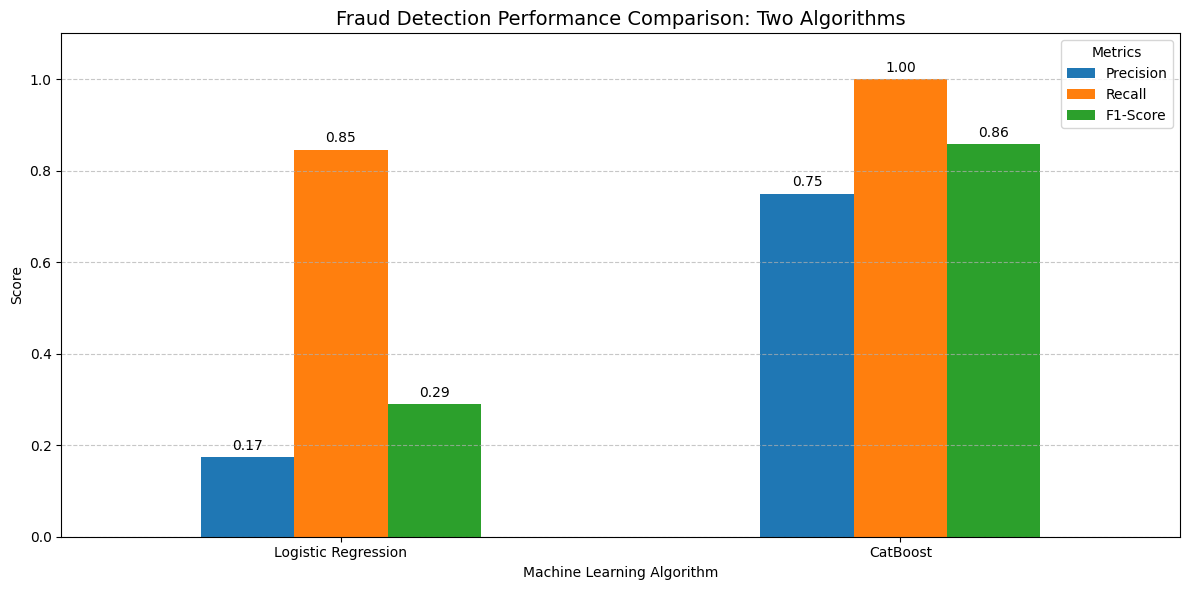

In [38]:
# ============================================================
# 3. PERFORMANCE COMPARISON DASHBOARD
# ============================================================

from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Calculate metrics for all 3 models
# ------------------------------------------------------------

metrics_list = []

for name, model in models.items():

    # Make predictions on test data
    test_preds = model.predict(X_test_imputed)

    # Convert predictions to 1D
    test_preds = test_preds.ravel()

    # Classification report
    report = classification_report(
        y_test,
        test_preds,
        output_dict=True
    )

    # --------------------------------------------------------
    # Handle binary class labels
    # --------------------------------------------------------

    # If your fraud class is represented as 1
    if '1' in report:
        fraud_precision = report['1']['precision']
        fraud_recall = report['1']['recall']
        fraud_f1 = report['1']['f1-score']

    # If labels are strings instead
    elif 'Fraud' in report:
        fraud_precision = report['Fraud']['precision']
        fraud_recall = report['Fraud']['recall']
        fraud_f1 = report['Fraud']['f1-score']

    else:
        raise ValueError(
            "Fraud class label was not found. "
            "Check your y_test class labels."
        )

    # Store results
    metrics_list.append({
        'Model': name,
        'Precision': fraud_precision,
        'Recall': fraud_recall,
        'F1-Score': fraud_f1
    })


# ============================================================
# CREATE COMPARISON DATAFRAME
# ============================================================

df_comparison = pd.DataFrame(
    metrics_list
).set_index('Model')


# Display numerical results
print("\nFraud Detection Performance Comparison:")
display(
    df_comparison.style.format("{:.4f}")
)


# ============================================================
# PERFORMANCE COMPARISON GRAPH
# ============================================================

ax = df_comparison.plot(
    kind='bar',
    figsize=(12, 6),
    rot=0
)

plt.title(
    'Fraud Detection Performance Comparison: Two Algorithms',
    fontsize=14
)

plt.xlabel(
    'Machine Learning Algorithm'
)

plt.ylabel(
    'Score'
)

plt.ylim(
    0,
    1.1
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.7
)

plt.legend(
    title='Metrics'
)


# Add values on bars
for container in ax.containers:

    ax.bar_label(
        container,
        fmt='%.2f',
        padding=3
    )


plt.tight_layout()
plt.show()

Creating train/test split...
Training Logistic Regression...
Training CatBoost...


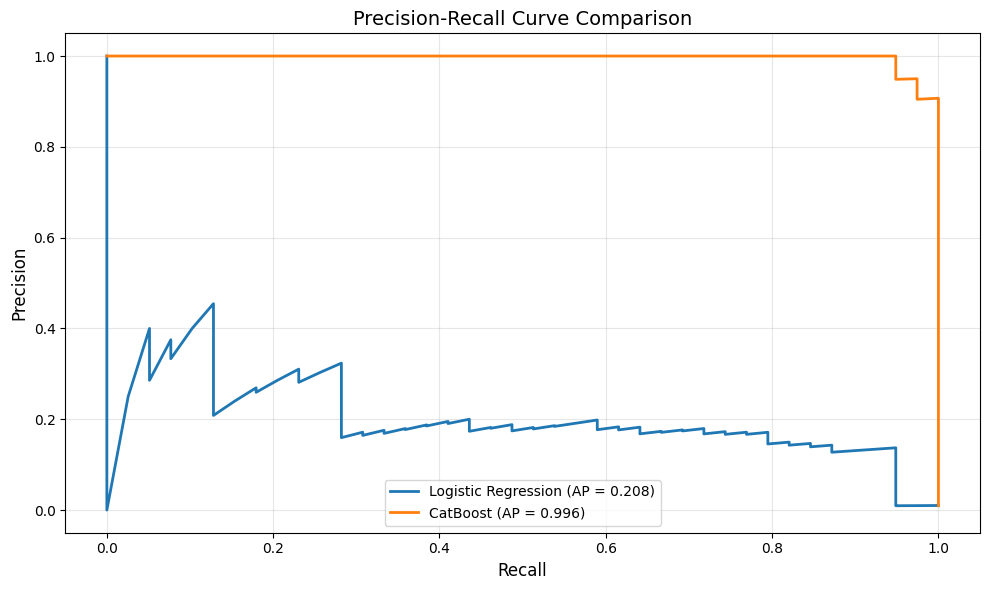


PRECISION-RECALL PERFORMANCE
Logistic Regression  AP: 0.2082
CatBoost             AP: 0.9963

Model Ranking:
          Algorithm  Average Precision
           CatBoost           0.996333
Logistic Regression           0.208243

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4019
           1       0.40      0.10      0.16        39

    accuracy                           0.99      4058
   macro avg       0.70      0.55      0.58      4058
weighted avg       0.99      0.99      0.99      4058


CATBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4019
           1       0.97      0.95      0.96        39

    accuracy                           1.00      4058
   macro avg       0.99      0.97      0.98      4058
weighted avg       1.00      1.00      1.00      4058


FINAL MODEL COMPARISON
          Algorithm 

In [39]:
# ============================================================
# FULL CODE
# Precision-Recall Curve Comparison
# Naive Bayes vs Logistic Regression vs CatBoost
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from catboost import CatBoostClassifier


# ============================================================
# 2. USE YOUR EXISTING DATA
# ============================================================

# If X_test_final and y_test_full already exist, use them.
# Otherwise, the code will create train/test data from X and y.

if 'X_test_final' in globals() and 'y_test_full' in globals():

    print("Using existing X_test_final and y_test_full...")

    X_test = X_test_final
    y_test = y_test_full

    # Try to find existing training data
    if 'X_train_final' in globals() and 'y_train_full' in globals():

        X_train = X_train_final
        y_train = y_train_full

    elif 'X_train' in globals() and 'y_train' in globals():

        X_train = X_train
        y_train = y_train

    else:

        print("Training data variables not found.")
        print("Creating training data from available X and y...")

        if 'X' not in globals() or 'y' not in globals():
            raise NameError(
                "Training data not found. Please make sure your dataset "
                "is stored in variables X and y."
            )

        X_train, _, y_train, _ = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )

else:

    # --------------------------------------------------------
    # If test data does not already exist
    # --------------------------------------------------------

    if 'X' not in globals() or 'y' not in globals():

        raise NameError(
            "Dataset not found. Please make sure your features "
            "are stored in X and target in y."
        )

    print("Creating train/test split...")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )


# ============================================================
# 3. Convert Data to Numeric
# ============================================================

# This is important for Naive Bayes and Logistic Regression.

if isinstance(X_train, pd.DataFrame):

    X_train = X_train.copy()
    X_test = X_test.copy()

    # Convert categorical columns to numeric
    X_train = pd.get_dummies(
        X_train,
        drop_first=True
    )

    X_test = pd.get_dummies(
        X_test,
        drop_first=True
    )

    # Make sure train and test have identical columns
    X_train, X_test = X_train.align(
        X_test,
        join='left',
        axis=1,
        fill_value=0
    )


# Convert to NumPy arrays
X_train = np.asarray(X_train)
X_test = np.asarray(X_test)

y_train = np.asarray(y_train)
y_test = np.asarray(y_test)


# ============================================================
# 4. Handle Missing / Infinite Values
# ============================================================

X_train = np.nan_to_num(
    X_train,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

X_test = np.nan_to_num(
    X_test,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)


# ============================================================
# 5. Feature Scaling for Logistic Regression
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


# ============================================================
# 6. Create Models
# ============================================================

logistic_regression = LogisticRegression(
    max_iter=1000,
    random_state=42
)

catboost_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=False,
    random_seed=42
)


# ============================================================
# 7. Train Logistic Regression
# ============================================================

print("Training Logistic Regression...")

logistic_regression.fit(
    X_train_scaled,
    y_train
)


# ============================================================
# 8. Train CatBoost
# ============================================================

print("Training CatBoost...")

catboost_model.fit(
    X_train,
    y_train
)


# ============================================================
# 9. Generate Probability Predictions
# ============================================================

y_probs_lr = logistic_regression.predict_proba(
    X_test_scaled
)[:, 1]

y_probs_cb = catboost_model.predict_proba(
    X_test
)[:, 1]


# ============================================================
# 10. Calculate Precision-Recall Curves
# ============================================================

precision_lr, recall_lr, _ = precision_recall_curve(
    y_test,
    y_probs_lr
)

precision_cb, recall_cb, _ = precision_recall_curve(
    y_test,
    y_probs_cb
)


# ============================================================
# 11. Calculate Average Precision
# ============================================================

ap_lr = average_precision_score(
    y_test,
    y_probs_lr
)

ap_cb = average_precision_score(
    y_test,
    y_probs_cb
)


# ============================================================
# 12. Plot Precision-Recall Curves
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    recall_lr,
    precision_lr,
    linewidth=2,
    label=f'Logistic Regression (AP = {ap_lr:.3f})'
)

plt.plot(
    recall_cb,
    precision_cb,
    linewidth=2,
    label=f'CatBoost (AP = {ap_cb:.3f})'
)

plt.xlabel(
    'Recall',
    fontsize=12
)

plt.ylabel(
    'Precision',
    fontsize=12
)

plt.title(
    'Precision-Recall Curve Comparison',
    fontsize=14
)

plt.legend(
    loc='best'
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. Print Average Precision Scores
# ============================================================

print("\n" + "=" * 60)
print("PRECISION-RECALL PERFORMANCE")
print("=" * 60)

print(
    f"Logistic Regression  AP: {ap_lr:.4f}"
)

print(
    f"CatBoost             AP: {ap_cb:.4f}"
)

print("=" * 60)


# ============================================================
# 14. Compare Model Performance
# ============================================================

results = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression',
        'CatBoost'
    ],
    'Average Precision': [
        ap_lr,
        ap_cb
    ]
})

results = results.sort_values(
    by='Average Precision',
    ascending=False
)

print("\nModel Ranking:")
print(results.to_string(index=False))


# ============================================================
# 15. Classification Reports
# ============================================================

y_pred_lr = logistic_regression.predict(
    X_test_scaled
)

y_pred_cb = catboost_model.predict(
    X_test
)


print("\n" + "=" * 60)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)


print("\n" + "=" * 60)
print("CATBOOST CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_cb
    )
)


# ============================================================
# 16. Final Comparison Table
# ============================================================

comparison = pd.DataFrame({
    'Algorithm': [
        'Logistic Regression',
        'CatBoost'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_cb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_cb, zero_division=0)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_cb, zero_division=0)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_cb, zero_division=0)
    ],

    'Average Precision': [
        ap_lr,
        ap_cb
    ]
})


print("\n" + "=" * 80)
print("FINAL MODEL COMPARISON")
print("=" * 80)

print(
    comparison.round(4).to_string(index=False)
)

print("=" * 80)

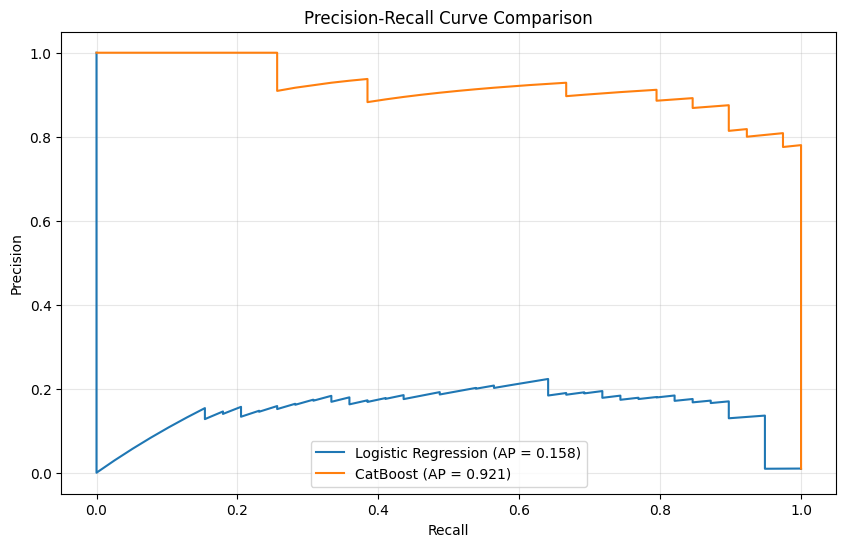

In [40]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# 4. Precision-Recall Curve Comparison
plt.figure(figsize=(10, 6))
for name, model in models.items():
    # Logistic Regression and Naive Bayes were trained on scaled data,
    # but CatBoost was trained on raw data in your last 'FULL CODE' run.
    # For consistency with your kernel state:
    if name == 'CatBoost':
        y_probs = model.predict_proba(X_test)[:, 1]
    else:
        y_probs = model.predict_proba(X_test_scaled)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_probs)
    ap = average_precision_score(y_test, y_probs)
    plt.plot(recall, precision, label=f'{name} (AP = {ap:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Feature Selection & Correlation Indicators
We now look at which individual features have the strongest statistical relationship with fraud.

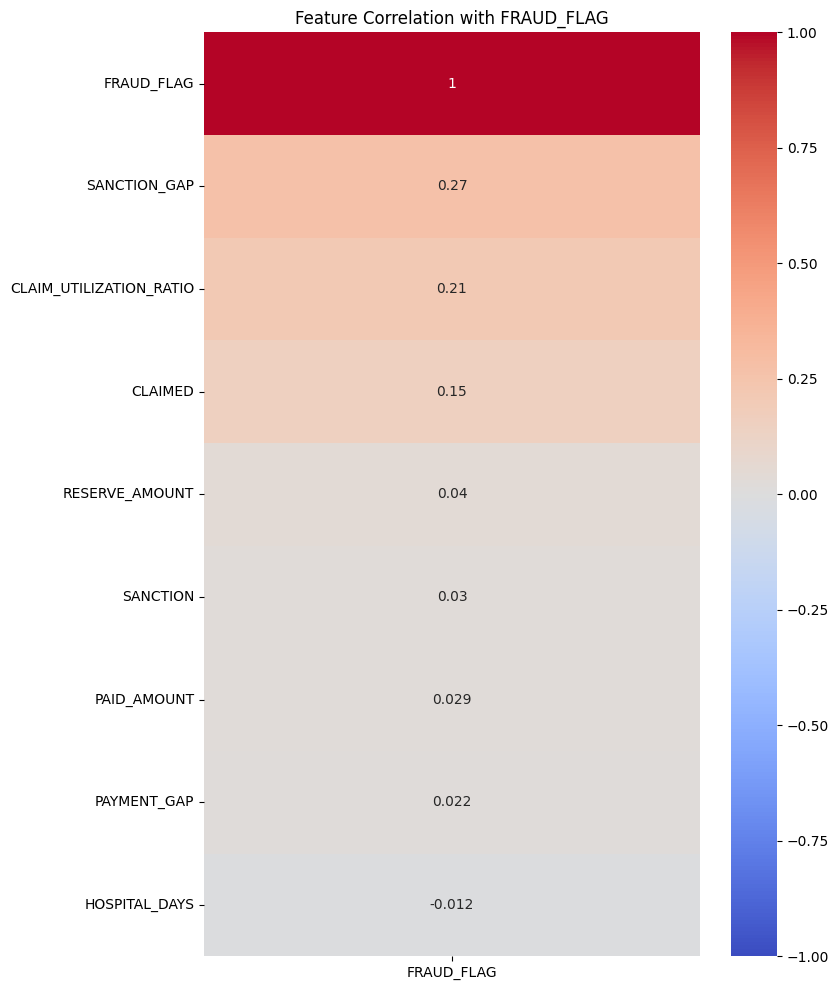

In [41]:
# 5. Correlation Heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 12))
# Using 'df' which is the active dataframe in the notebook
# Ensuring we only correlate numerical features used in the model plus the target
corr_cols = features + ['FRAUD_FLAG']
corr = df[corr_cols].corr()[['FRAUD_FLAG']].sort_values(by='FRAUD_FLAG', ascending=False)

sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation with FRAUD_FLAG')
plt.show()

### XAI: Explaining CatBoost with SHAP
SHAP values tell us exactly how much each feature contributed to the final fraud probability for the test set.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
LIME Explanation for Test Instance Index: 26


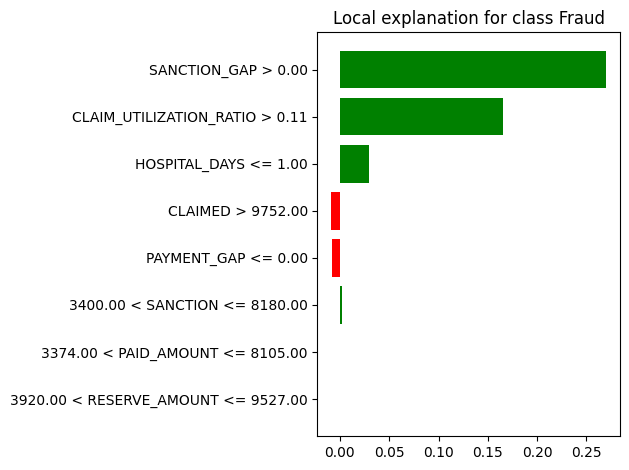

In [42]:
try:
    import lime
    import lime.lime_tabular
except ImportError:
    !pip install lime -q
    import lime
    import lime.lime_tabular

import numpy as np
import matplotlib.pyplot as plt

# 1. Use existing variables from the kernel state
# We use the trained CatBoost model from the 'models' dictionary
cat_model = models['CatBoost']

# 2. Initialize LIME Tabular Explainer
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_imputed,
    feature_names=features,
    class_names=['Non-Fraud', 'Fraud'],
    mode='classification'
)

# 3. Pick a fraud instance to explain (where prediction was 1)
test_preds = cat_model.predict(X_test_imputed).ravel()
fraud_indices = np.where(test_preds == 1)[0]

if len(fraud_indices) > 0:
    idx = fraud_indices[0]

    # 4. Generate LIME explanation
    exp = explainer_lime.explain_instance(
        X_test_imputed[idx],
        cat_model.predict_proba,
        num_features=10
    )

    # 5. Visualize individual explanation
    print(f'LIME Explanation for Test Instance Index: {idx}')
    exp.show_in_notebook(show_table=True)
    exp.as_pyplot_figure()
    plt.tight_layout()
    plt.show()
else:
    print('No fraud instances found in the test set to explain.')

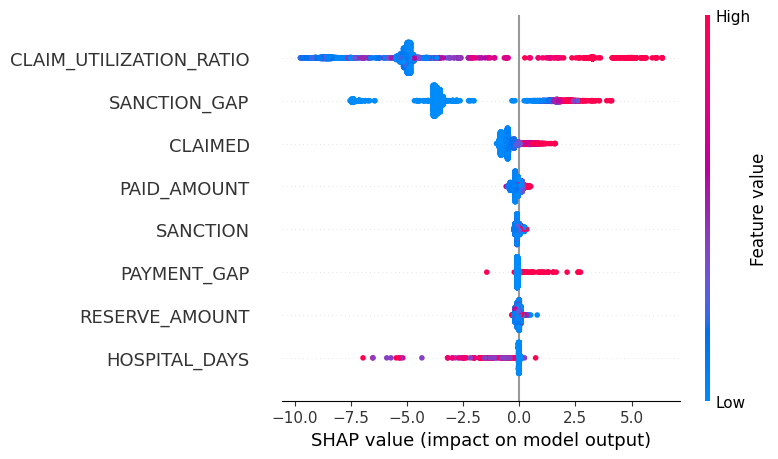

In [43]:
import shap
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Use the trained CatBoost model and data from your existing workspace
# The current CatBoost model is stored in the 'models' dictionary
cat_model = models['CatBoost']

# 2. Explainability (XAI) using SHAP
# We use TreeExplainer for CatBoost
explainer = shap.TreeExplainer(cat_model)

# Calculate SHAP values for the test set
# CatBoost models can handle X_test_imputed directly
shap_values = explainer.shap_values(X_test_imputed)

# 3. Convert X_test_imputed back to DataFrame for visualization
# The column names were previously stored in the 'features' list
X_test_df = pd.DataFrame(X_test_imputed, columns=features)

# 4. Generate Summary Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_df, show=True)

### Robust 5-Fold Cross-Validation
We will now validate the stability of CatBoost and Logistic Regression across different folds of the data to ensure the performance isn't a result of a specific train-test split.

In [45]:
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

# Define the cross-validation strategy
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ['precision', 'recall', 'f1']

cv_summary = []

# We iterate over the models dictionary defined in cell HfzI20Px4nk9
for name, model in models.items():
    print(f"Running Cross-Validation for {name}...")
    # Use the correctly named variables from the current kernel state
    cv_results = cross_validate(
        model,
        X_train_imputed,
        y_train,
        cv=skf,
        scoring=scoring_metrics
    )

    cv_summary.append({
        'Model': name,
        'Mean Precision': cv_results['test_precision'].mean(),
        'Mean Recall': cv_results['test_recall'].mean(),
        'Mean F1': cv_results['test_f1'].mean()
    })

# Display the final cross-validation results
df_cv_results = pd.DataFrame(cv_summary).set_index('Model')
display(df_cv_results)

Running Cross-Validation for Logistic Regression...
Running Cross-Validation for CatBoost...


,Mean Precision,Mean Recall,Mean F1
Model,,,
Logistic Regression,0.196735,0.867339,0.32017
CatBoost,0.766239,0.987500,0.86225


--- 5-Fold Stratified Cross-Validation Summary ---


,Mean Precision,Mean Recall,Mean F1
Model,,,
Logistic Regression,0.196735,0.867339,0.32017
CatBoost,0.766239,0.987500,0.86225


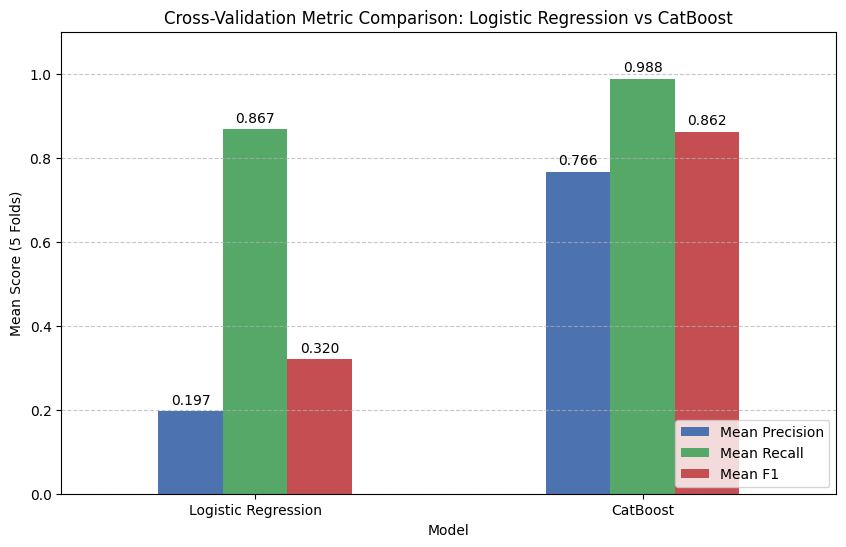

In [46]:
import matplotlib.pyplot as plt

# Display the numerical results
print("--- 5-Fold Stratified Cross-Validation Summary ---")
display(df_cv_results)

# Visualize the comparison
ax = df_cv_results.plot(kind='bar', figsize=(10, 6), rot=0, color=['#4C72B0', '#55A868', '#C44E52'])
plt.title('Cross-Validation Metric Comparison: Logistic Regression vs CatBoost')
plt.ylabel('Mean Score (5 Folds)')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')

# Add value labels
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.show()